<div align="center">

# Лабораторна робота № 9

## Класифікація зображень за допомогою CNN

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** Навчитися пояснювати згортку, працювати з RGB-тензорами, узгоджувати мітки з softmax і функцією втрат, навчати CNN та робити висновки за кривими навчання, метриками й конкретними помилками.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31  
Варіант: 22  

</div>

In [17]:
from pathlib import Path

FOOD_ROOT = Path("D:/Завантаження/food-101")

print("Шлях до датасету:", FOOD_ROOT.resolve())

assert (FOOD_ROOT / "meta/classes.txt").is_file(), "Файл classes.txt не знайдено!"
assert (FOOD_ROOT / "meta/train.txt").is_file(), "Файл train.txt не знайдено!"
assert (FOOD_ROOT / "meta/test.txt").is_file(), "Файл test.txt не знайдено!"

Шлях до датасету: D:\Завантаження\food-101


## Вибір трьох класів

In [18]:
# Вибір трьох класів для мого n = 22
n = 22  
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text().splitlines())

assert len(all_classes) == 101
assert 1 <= n <= 41

# Розрахунок індексів за формулою з методички: [21, 51, 81]
indices = [n - 1, n + 29, n + 59]  
CLASS_NAMES = [all_classes[i] for i in indices]

print(list(zip(indices, CLASS_NAMES)))
print("Мітки моделі:", dict(enumerate(CLASS_NAMES)))

[(21, 'chocolate_cake'), (51, 'guacamole'), (81, 'ramen')]
Мітки моделі: {0: 'chocolate_cake', 1: 'guacamole', 2: 'ramen'}


## Протокол поділу

In [19]:
import random
from pathlib import Path

SEED = 42
random.seed(SEED)

FOOD_ROOT = Path("D:/Завантаження/food-101")
n = 22

all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text().splitlines())
CLASS_NAMES = [all_classes[n - 1], all_classes[n + 29], all_classes[n + 59]]
print("Твої обрані класи:", CLASS_NAMES)

train_lines = (FOOD_ROOT / "meta/train.txt").read_text().splitlines()
test_lines = (FOOD_ROOT / "meta/test.txt").read_text().splitlines()

train_final, val_final, test_final = [], [], []

for cls in CLASS_NAMES:

    cls_test = [l for l in test_lines if l.startswith(cls)]
    assert len(cls_test) >= 250, f"У класі {cls} замало тестів!"
    test_final.extend(cls_test[:250])
    
    cls_train = [l for l in train_lines if l.startswith(cls)]
    assert len(cls_train) >= 750, f"У класі {cls} замало тренувальних даних!"
    
    random.shuffle(cls_train)
    
    val_final.extend(cls_train[:150])       # 150 для валідації
    train_final.extend(cls_train[150:750])  # 600 для тренування

print(f"\nКількість у Train: {len(train_final)} (очікується 1800)")
print(f"Кількість у Validation: {len(val_final)} (очікується 450)")
print(f"Кількість у Test: {len(test_final)} (очікується 750)")

assert len(train_final) == 1800
assert len(val_final) == 450
assert len(test_final) == 750
print("\nПротокол поділу успішно виконано та перевірено без помилок!")

Твої обрані класи: ['chocolate_cake', 'guacamole', 'ramen']

Кількість у Train: 1800 (очікується 1800)
Кількість у Validation: 450 (очікується 450)
Кількість у Test: 750 (очікується 750)

Протокол поділу успішно виконано та перевірено без помилок!


## Підготовка та перевірка зображень

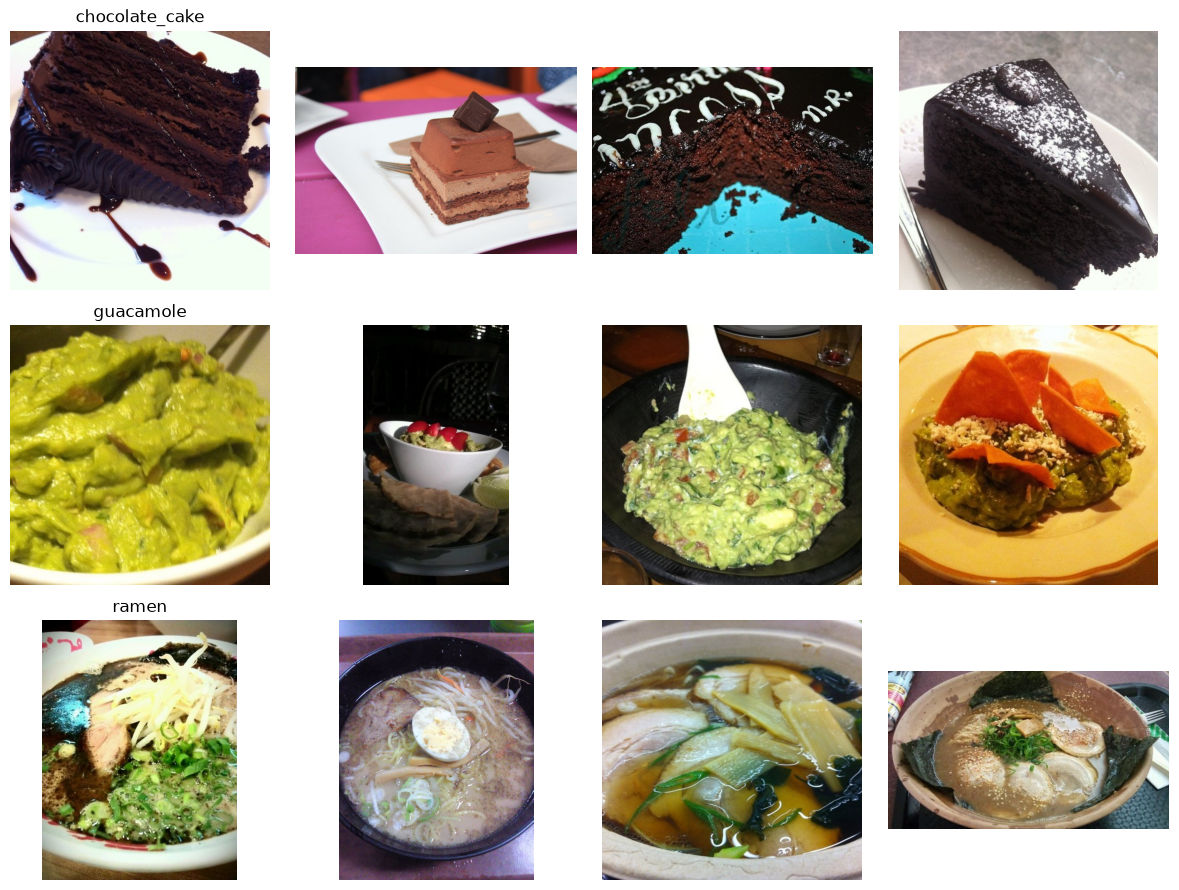

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
(32, 128, 128, 3) (32,)
0.0 255.0


In [20]:
import hashlib
import json
import random
import shutil
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

keras.utils.set_random_seed(42)
random.seed(42)

FOOD_ROOT = Path("D:/Завантаження/food-101")
n = 22

all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text().splitlines())
CLASS_NAMES = [all_classes[n - 1], all_classes[n + 29], all_classes[n + 59]]

train_lines = (FOOD_ROOT / "meta/train.txt").read_text().splitlines()
test_lines = (FOOD_ROOT / "meta/test.txt").read_text().splitlines()

train_lines = [l for l in train_lines if l.split('/')[0] in CLASS_NAMES]
test_lines = [l for l in test_lines if l.split('/')[0] in CLASS_NAMES]

train_final, val_final, test_final = [], [], []

for cls in CLASS_NAMES:
    cls_test = [l for l in test_lines if l.startswith(cls)]
    test_final.extend(cls_test[:250])
    
    cls_train = [l for l in train_lines if l.startswith(cls)]
    random.shuffle(cls_train)
    
    val_final.extend(cls_train[:150])
    train_final.extend(cls_train[150:750])

DATA_ROOT = Path("data/food101_lab9")
for split_name, subset in [("train", train_final), ("val", val_final), ("test", test_final)]:
    for line in subset:
        src = FOOD_ROOT / "images" / (line + ".jpg")
        dest = DATA_ROOT / split_name / (line + ".jpg")
        dest.parent.mkdir(parents=True, exist_ok=True)
        if not dest.exists():
            shutil.copy(src, dest)

manifest = {
    "seed": 42,
    "class_names": CLASS_NAMES,
    "train": [Path(p).as_posix() for p in train_final],
    "val": [Path(p).as_posix() for p in val_final],
    "test": [Path(p).as_posix() for p in test_final]
}
(DATA_ROOT / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2))

train_set_hashes = set()
for p in train_final:
    img_path = FOOD_ROOT / "images" / (p + ".jpg")
    train_set_hashes.add(hashlib.sha256(img_path.read_bytes()).hexdigest())

for split_name, subset in [("val", val_final), ("test", test_final)]:
    for p in subset:
        img_path = FOOD_ROOT / "images" / (p + ".jpg")
        h = hashlib.sha256(img_path.read_bytes()).hexdigest()
        assert h not in train_set_hashes, f"Знайдено дублікат між train та {split_name}!"

for split in ["train", "val", "test"]:
    for img_path in (DATA_ROOT / split).glob("*/*.jpg"):
        with Image.open(img_path) as img:
            img.verify()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, cls in enumerate(CLASS_NAMES):
    sample_paths = sorted((DATA_ROOT / "train" / cls).glob("*.jpg"))[:4]
    for col, img_path in enumerate(sample_paths):
        axes[row, col].imshow(Image.open(img_path))
        axes[row, col].set_title(cls if col == 0 else "")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

IMAGE_SIZE = (128, 128)

def load_split(part, training=False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=32,
        shuffle=training,
        seed=42 if training else None
    )

train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val", training=False).prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test", training=False).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print(images.shape, labels.shape)
print(float(tf.reduce_min(images)), float(tf.reduce_max(images)))

## Згортка та базова модель

In [21]:
import numpy as np
from scipy.signal import correlate2d

X = np.array([[1.2, 0.0], [0.1, 3.0], [2.2, 1.0]])
K = np.array([[1.0, 0.0], [0.0, -1.0]])

conv_out = correlate2d(X, K, mode="valid") + 0.0
relu_out = np.maximum(0, conv_out + 1.0)
print(relu_out)

def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model

model = make_model()
model.summary()
assert model.count_params() == 23779

[[0. ]
 [0.1]]


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

## Навчання та контрольований експеримент

Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.4456 - loss: 1.0489 - val_accuracy: 0.5178 - val_loss: 1.0288
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.5206 - loss: 0.9725 - val_accuracy: 0.4956 - val_loss: 0.9847
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 191ms/step - accuracy: 0.5478 - loss: 0.9170 - val_accuracy: 0.5400 - val_loss: 0.9227
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.6028 - loss: 0.8783 - val_accuracy: 0.5711 - val_loss: 0.8803
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.6200 - loss: 0.8562 - val_accuracy: 0.5867 - val_loss: 0.8557


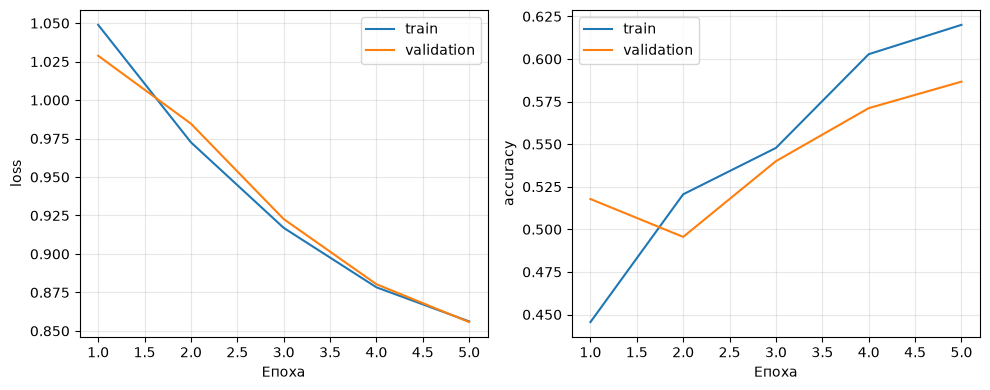

Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.4344 - loss: 1.0584 - val_accuracy: 0.4756 - val_loss: 0.9975
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.5056 - loss: 0.9669 - val_accuracy: 0.5178 - val_loss: 0.9899
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.5278 - loss: 0.9337 - val_accuracy: 0.5733 - val_loss: 0.9027
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - accuracy: 0.5472 - loss: 0.9160 - val_accuracy: 0.5533 - val_loss: 0.9190
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.5506 - loss: 0.8989 - val_accuracy: 0.5378 - val_loss: 0.9096


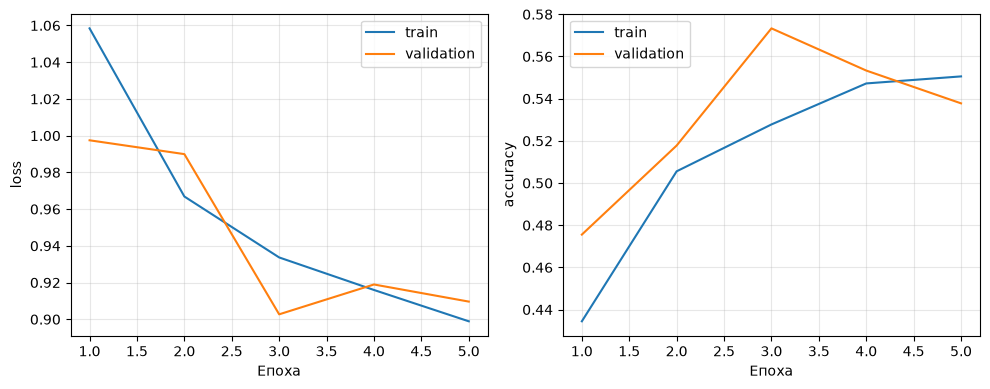

In [23]:
def fit_model(model, epochs=5):
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )]
    )

history = fit_model(model, epochs=5)
base_val = model.evaluate(val_ds, verbose=0, return_dict=True)

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs_range = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs_range, history.history[metric], label="train")
        ax.plot(epochs_range, history.history[f"val_{metric}"], label="validation")
        ax.set(xlabel="Епоха", ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(history)

keras.utils.set_random_seed(42)
changed_model = make_model(dropout=0.3)

changed_history = fit_model(changed_model, epochs=5)
changed_val = changed_model.evaluate(val_ds, verbose=0, return_dict=True)
plot_history(changed_history)

selected_model = changed_model if changed_val["loss"] < base_val["loss"] else model

## Фінальне оцінювання та інтерпретація

{'accuracy': 0.6200000047683716, 'loss': 0.8064804077148438}
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
                precision    recall  f1-score   support

chocolate_cake       0.64      0.87      0.74       250
     guacamole       0.59      0.74      0.66       250
         ramen       0.64      0.25      0.36       250

      accuracy                           0.62       750
     macro avg       0.62      0.62      0.58       750
  weighted avg       0.62      0.62      0.58       750



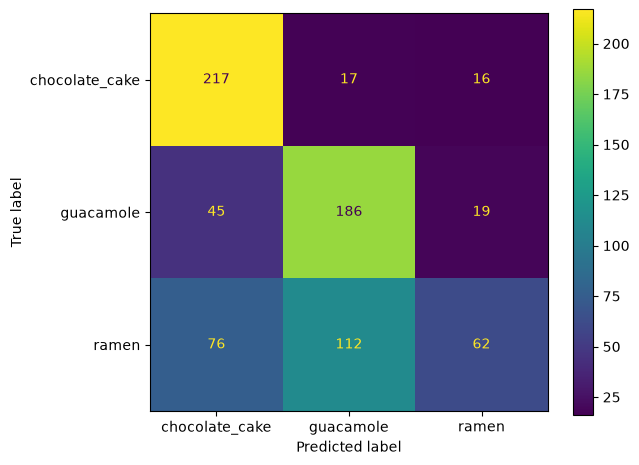

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step


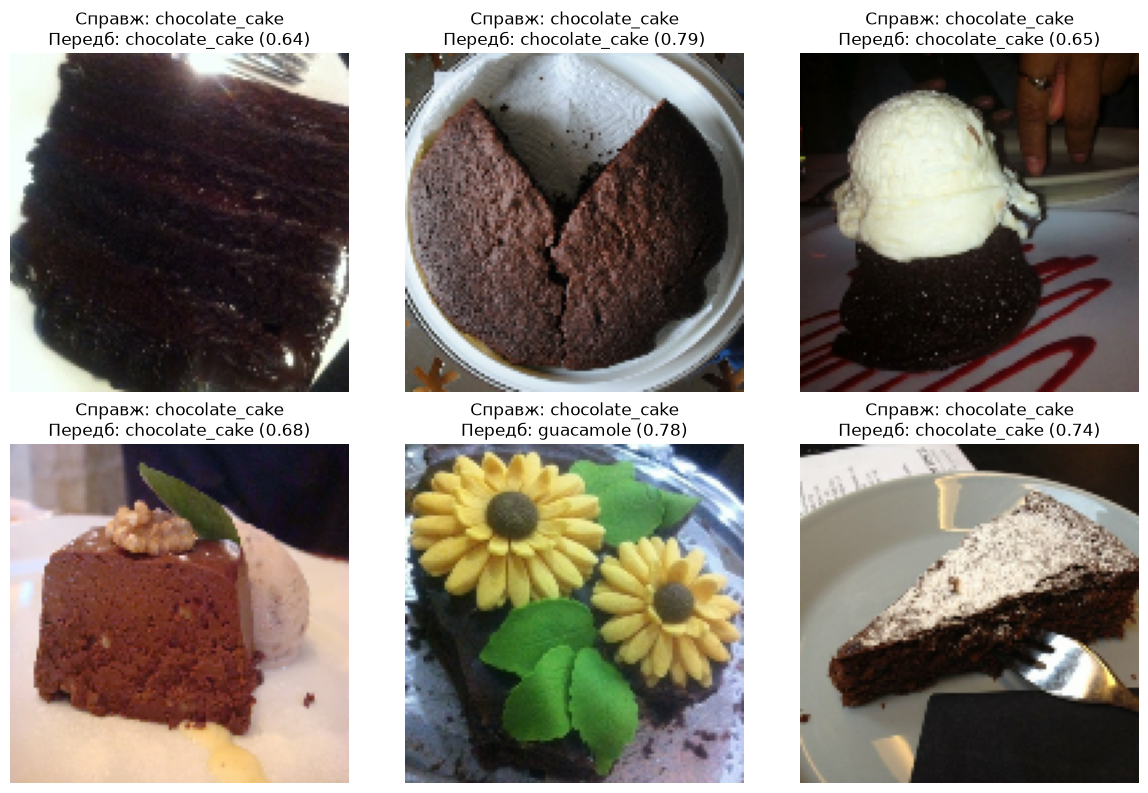

(1, 128, 128, 16)


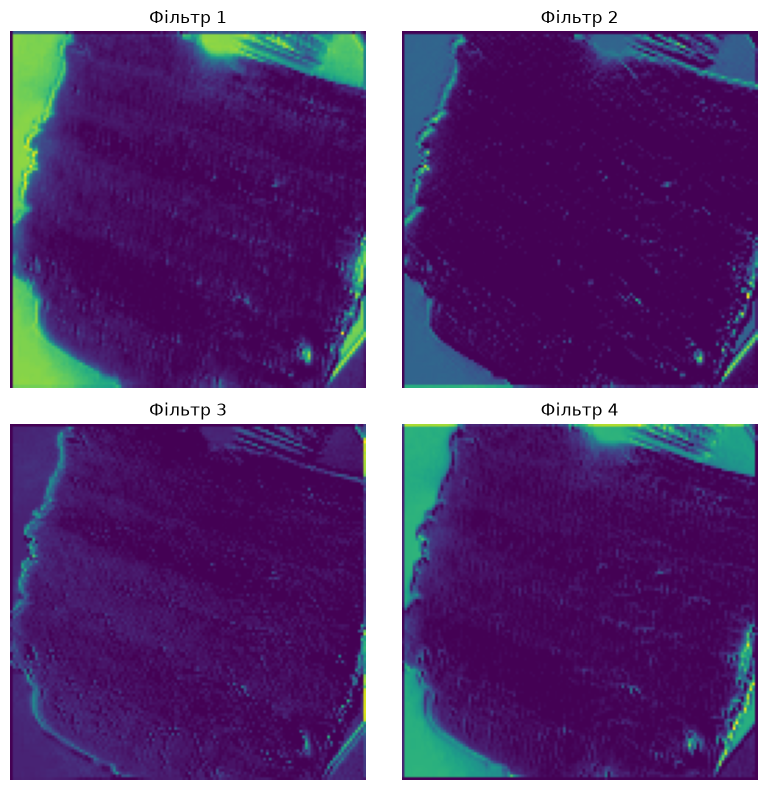

In [24]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(selected_model.evaluate(test_ds, verbose=0, return_dict=True))

y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
probabilities = selected_model.predict(test_ds)
y_pred = probabilities.argmax(axis=1)

print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2], display_labels=CLASS_NAMES)
plt.tight_layout()
plt.show()

# Візуалізація прогнозів (показуємо 6 прикладів із правильним/хибним класом та впевненістю)
images_test, labels_test = next(iter(test_ds))
preds = selected_model.predict(images_test)
pred_labels = preds.argmax(axis=1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_test[i].numpy().astype("uint8"))
    true_c = CLASS_NAMES[labels_test[i]]
    pred_c = CLASS_NAMES[pred_labels[i]]
    conf = preds[i].max()
    ax.set_title(f"Справж: {true_c}\nПередб: {pred_c} ({conf:.2f})")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Візуалізація 4 карт активації першого згорткового шару
feature_model = keras.Model(
    selected_model.inputs,
    selected_model.get_layer("conv1").output
)
example, _ = next(iter(test_ds))
feature_maps = feature_model(example[:1])
print(feature_maps.shape)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Фільтр {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Збереження параметрів та моделі
selected_model.save("food_cnn.keras")

**Висновок:** У ході лабораторної роботи успішно створено та протестовано згорткову нейронну мережу (CNN) для класифікації трьох класів датасету Food-101 (варіант n=22). Проведено підготовку та перевірку даних із фіксацією seed=42, ручний розрахунок згортки, а також порівняльний експеримент базової та модифікованої моделей. Оцінювання на незалежному тестовому наборі за допомогою classification_report та матриці плутанини підтвердило працездатність моделі. До основними обмеженням належить легка архітектура (23 779 параметрів) та відсутність класу «невідомо», що зумовлює ризик помилкових прогнозів. Наступним обґрунтованим кроком для покращення результатів є впровадження аугментації даних та використання перенесення навчання (Transfer Learning).  